In [2]:
from __future__ import annotations

import os
import shutil
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from config.config import RUN_DIR

In [23]:
def plot_detaild_analysis(
    metrics_df: pd.DataFrame,
    metric: str,
    run_col_name: str,
    experiment_col: str,
    left_col: str,
    right_col: str,
    left_col_name: str,
    right_col_name: str,
    run_separator: str = "__",
    precision: int = 2,
) -> None:
    metrics_df[run_col_name] = metrics_df[left_col].str.cat(metrics_df[right_col], sep=run_separator)

    metrics_df[left_col_name] = metrics_df[run_col_name].str.split(run_separator).str[0]
    metrics_df[right_col_name] = metrics_df[run_col_name].str.split(run_separator).str[1]

    fig, axes = plt.subplots(4, 2, figsize=(28, 34))
    fig.suptitle("Metric Analysis Across Models, Experiments, and Experiment Splits", fontsize=16)
    axes = axes.flatten()

    # 1. Box Plot + Points: {metric}s Per Model
    sns.boxplot(
        ax=axes[0],
        data=metrics_df,
        x=run_col_name,
        y=metric,
        palette="viridis",
        width=0.6,
        hue=run_col_name,
        legend=False,
    )
    sns.stripplot(ax=axes[0], data=metrics_df, x=run_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
    axes[0].set_title(f"{metric} Distribution Per {run_col_name}")
    axes[0].tick_params(axis="x", rotation=34)

    # 2. Box Plot + Points: {metric}s Per Experiment Type
    sns.boxplot(
        ax=axes[1],
        data=metrics_df,
        x=experiment_col,
        y=metric,
        palette="coolwarm",
        width=0.6,
        hue=experiment_col,
        legend=False,
    )
    sns.stripplot(
        ax=axes[1], data=metrics_df, x=experiment_col, y=metric, color="black", alpha=0.5, jitter=True, size=4
    )
    axes[1].set_title(f"{metric} Distribution Per {experiment_col}")
    axes[1].tick_params(axis="x", rotation=34)

    # 3. Heatmap: Metric Performance (Model vs. Experiment)
    pivot_table = metrics_df.pivot_table(index=run_col_name, columns=experiment_col, values=metric, sort=True)
    sns.heatmap(ax=axes[2], data=pivot_table, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[2].set_title(f"{metric.title()} Heatmap ({run_col_name} vs. {experiment_col})")
    axes[2].set_xlabel(f"{experiment_col}")
    axes[2].set_ylabel(f"{run_col_name}")

    # 4. Histogram: Overall Distribution of {metric}s
    sns.histplot(ax=axes[3], data=metrics_df[metric], bins=20, kde=True, color="purple")
    axes[3].set_title(f"Overall Distribution of {metric}s")
    axes[3].set_xlabel(f"{metric}")
    axes[3].set_ylabel("Frequency")

    # 5. Heatmap: Metric Performance ({left_col} vs. {right_col})
    pivot_table_lr = metrics_df.pivot_table(index=left_col_name, columns=right_col_name, values=metric)
    sns.heatmap(ax=axes[4], data=pivot_table_lr, cmap="Blues", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[4].set_title(f"Performance Heatmap ({left_col} vs. {right_col})")
    axes[4].set_xlabel(f"{right_col}")
    axes[4].set_ylabel(f"{left_col}")
    axes[4].tick_params(axis="x", rotation=34)

    # 6. Heatmap: Model Performance by Left & {right_col}
    pivot_table_left = metrics_df.pivot_table(index=run_col_name, columns=left_col_name, values=metric)
    pivot_table_right = metrics_df.pivot_table(index=run_col_name, columns=right_col_name, values=metric)
    combined = pd.concat([pivot_table_left, pivot_table_right], axis=1)

    sns.heatmap(ax=axes[5], data=combined, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    axes[5].set_title(f"Model Performance Heatmap (Grouped by {left_col})")
    axes[5].set_xlabel(f"{left_col}")
    axes[5].set_ylabel(f"{run_col_name}")
    axes[5].tick_params(axis="x", rotation=34)

    # 7. Box Plot: {metric}s Grouped by {left_col}
    sns.boxplot(
        ax=axes[6],
        data=metrics_df,
        x=left_col_name,
        y=metric,
        palette="viridis",
        width=0.6,
        hue=left_col_name,
        legend=False,
    )
    sns.stripplot(ax=axes[6], data=metrics_df, x=left_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4)
    axes[6].set_title(f"{metric} Distribution (Grouped by {left_col})")
    axes[6].set_xlabel(f"{left_col}")

    axes[6].tick_params(axis="x", rotation=34)

    # 8. Box Plot: {metric}s Grouped by {right_col}
    sns.boxplot(
        ax=axes[7],
        data=metrics_df,
        x=right_col_name,
        y=metric,
        palette="coolwarm",
        width=0.6,
        hue=right_col_name,
        legend=False,
    )
    sns.stripplot(
        ax=axes[7], data=metrics_df, x=right_col_name, y=metric, color="black", alpha=0.5, jitter=True, size=4
    )
    axes[7].set_title(f"{metric} Distribution (Grouped by {right_col})")
    axes[7].set_xlabel(f"{right_col}")
    axes[7].tick_params(axis="x", rotation=34)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [30]:
metrics_df = pd.read_csv(RUN_DIR / "all_runs_metrics_reduced.csv")
metrics_df.head()

,Experiment,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,SubSet,Model,Run
0,direct_entity,0.7905,0.7778,0.9448,0.8532,0.5111,0.9448,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
1,direct_entity_ontological,0.7866,0.7946,0.9018,0.8448,0.5778,0.9018,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
2,direct_entity_with_synonyms,0.8024,0.7729,0.9816,0.8649,0.4778,0.9816,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
3,sequential_hierarchy,0.8024,0.7783,0.9693,0.8634,0.5000,0.9693,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28
4,sequential_hierarchy_ontological,0.7628,0.7696,0.9018,0.8305,0.5111,0.9018,anatomy,human-mouse,gemini-2.0-flash,2025-04-04_19-41-28


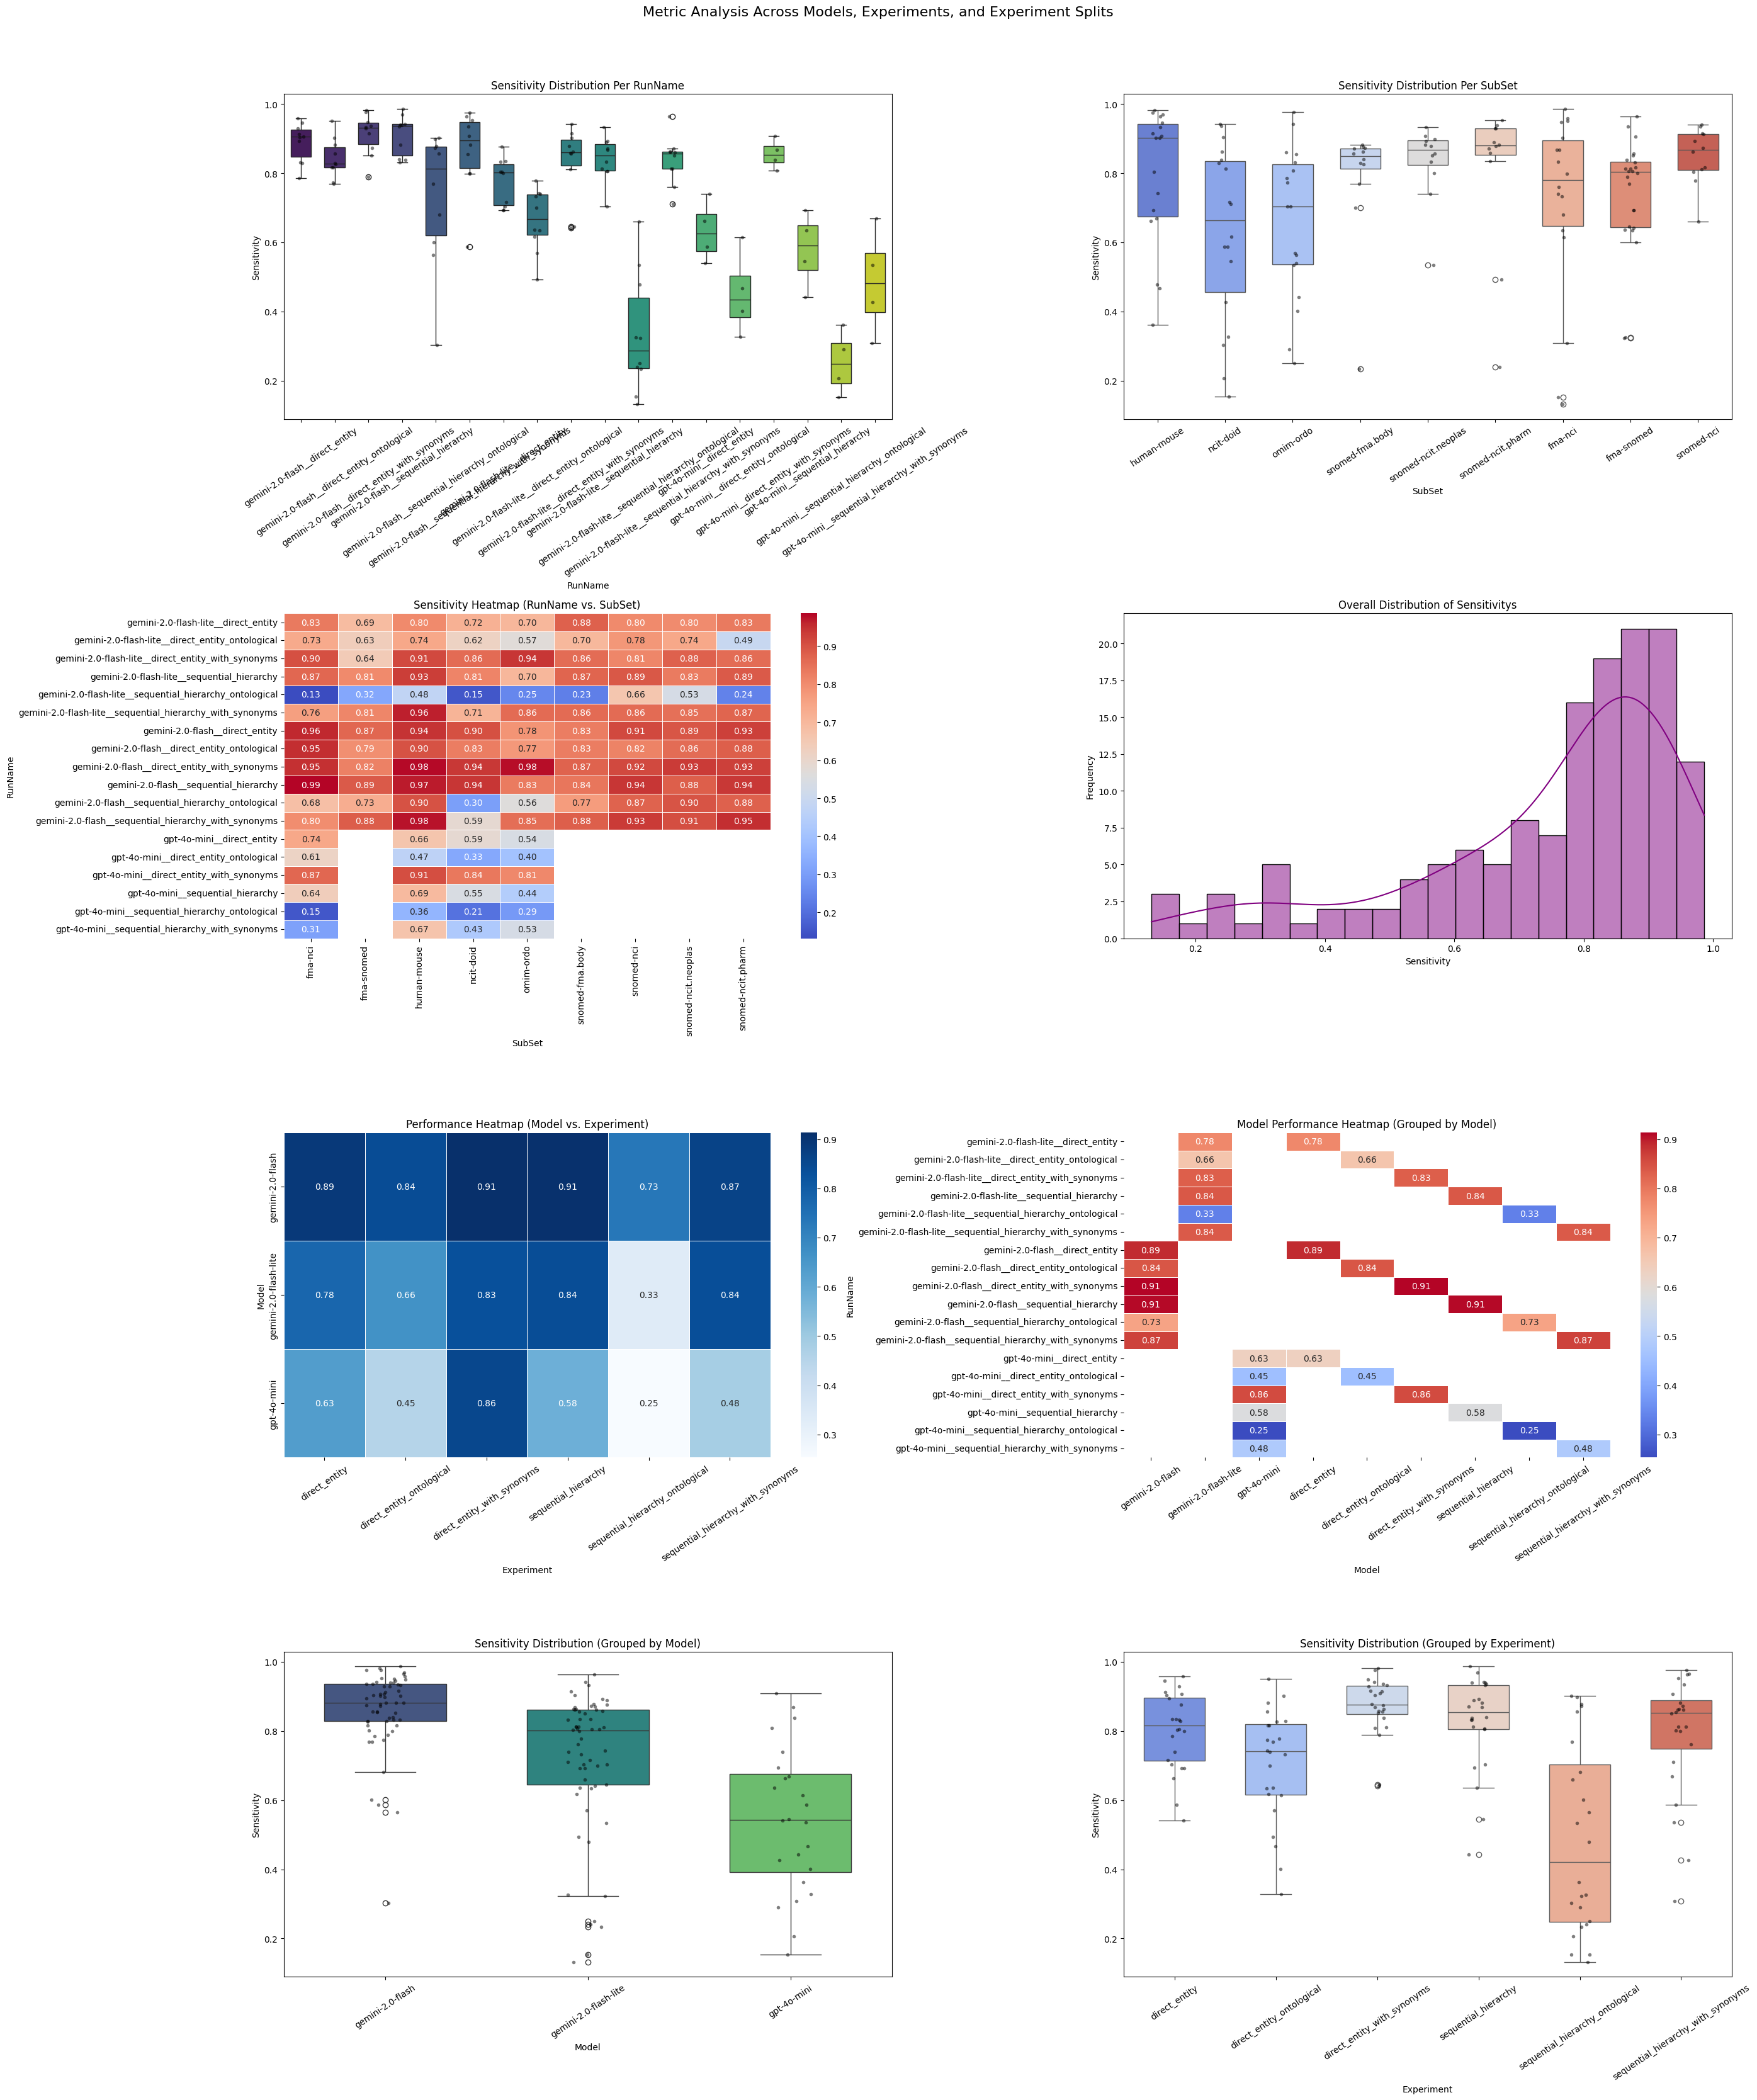

In [31]:
metric = "Sensitivity"
experiment_col, left_col, right_col = "Experiment", "SubSet", "Model"
experiment_col, left_col, right_col = "SubSet", "Model", "Experiment"

plot_detaild_analysis(
    metrics_df=metrics_df,
    metric=metric,
    run_col_name="RunName",
    experiment_col=experiment_col,
    left_col=left_col,
    right_col=right_col,
    left_col_name="leftPart",
    right_col_name="rightPart",
    run_separator="__",
)

### Copy best results

In [ ]:
prompt_type = "direct_entity_with_synonyms"
model = "gemini-2.0-flash_"

RUNS_METADATA = [
    ("2025-05-01_11-47-16", "gemini-2.0-flash", "snomed-nci", "largebio"),
    ("2025-05-01_11-37-30", "gemini-2.0-flash-lite", "snomed-nci", "largebio"),
    ("2025-05-01_11-24-31", "gemini-2.0-flash", "fma-snomed", "largebio"),
    ("2025-05-01_11-19-48", "gemini-2.0-flash-lite", "fma-snomed", "largebio"),
    ("2025-05-01_11-15-05", "gemini-2.0-flash", "snomed-ncit.pharm", "bioml-2024"),
    ("2025-05-01_11-12-35", "gemini-2.0-flash-lite", "snomed-ncit.pharm", "bioml-2024"),
    ("2025-05-01_11-07-00", "gemini-2.0-flash", "snomed-ncit.neoplas", "bioml-2024"),
    ("2025-05-01_11-06-39", "gemini-2.0-flash-lite", "snomed-ncit.neoplas", "bioml-2024"),
    ("2025-05-01_10-56-46", "gemini-2.0-flash", "snomed-fma.body", "bioml-2024"),
    ("2025-05-01_10-50-33", "gemini-2.0-flash-lite", "snomed-fma.body", "bioml-2024"),
    ("2025-05-01_10-13-02", "gemini-2.0-flash-lite", "fma-snomed", "largebio"),
    ("2025-04-10_22-11-36", "gemini-2.0-flash", "ncit-doid", "bioml-2024"),
    ("2025-04-10_00-33-19", "gemini-2.0-flash-lite", "ncit-doid", "bioml-2024"),
    ("2025-04-06_22-05-02", "gemini-2.0-flash-lite", "omim-ordo", "bioml-2024"),
    ("2025-04-06_19-27-41", "gemini-2.0-flash", "omim-ordo", "bioml-2024"),
    ("2025-04-06_14-51-00", "gemini-2.0-flash-lite", "fma-nci", "largebio"),
    ("2025-04-06_14-18-46", "gemini-2.0-flash", "fma-nci", "largebio"),
    ("2025-04-04_19-41-28", "gemini-2.0-flash", "human-mouse", "anatomy"),
    ("2025-04-04_19-23-47", "gemini-2.0-flash-lite", "human-mouse", "anatomy"),
    ("2025-04-04_00-43-16", "gemini-2.0-flash", "fma-snomed", "largebio"),
    ("2025-03-28_10-15-04", "gpt-4o-mini", "fma-nci", "largebio"),
    ("2025-03-19_23-32-20", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
    ("2025-03-19_22-17-52", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-19_19-48-41", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-14_00-40-55", "gpt-4o-mini", "ncit-doid", "bioml-2024"),
    ("2025-03-12_17-21-53", "gpt-4o-mini", "human-mouse", "anatomy"),
    ("2025-03-12_14-43-32", "gpt-4o-mini", "omim-ordo", "bioml-2024"),
]


In [29]:
for run_metadata in RUNS_METADATA:
    run_name, model_name, subset_name, experiment_name = run_metadata
    run_dir = Path("../runs") / run_name
    for file in run_dir.iterdir():
        if prompt_type in file and model in file and file.endswith(".csv"):
            print(f"Processing {file} in {file}")
            new_file_path = Path("best_results") / file
            new_file_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(run_dir / file, new_file_path)

Processing snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in snomed-nci_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in fma-snomed_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results.csv in snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results.csv
Processing snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv in snomed-ncit.pharm_gemini-2.0-flash_direct_entity_with_synonyms_results_reduced.csv
Processing snomed-ncit.n

## Gather outputs results

In [26]:
outputs_dir = Path("./outputs")
datasets_map = {"anatomy": ["human-mouse"], "largebio": ["fma-nci"], "bioml-2024": ["omim-ordo"]}
models = ["gemini-2.0-flash-lite", "gemini-2.0-flash"]
experiments_subtypes = {"syspromts" : ["base", "natural_language", "ontology_aware", "synonym_aware", "none"]}
experiments_subtypes = {"determinism" : ["0", "1", "2", "3"]}

dfs = []

for dataset, subsets_map in datasets_map.items():
    for set_name in subsets_map:
        for model in models:
            for experiment_type in experiments_subtypes:
                for experiment in experiments_subtypes[experiment_type]:
                    run_subdir = f"{dataset}/{set_name}/{model}/{experiment_type}/{experiment}"
                    metrics_df = pd.read_csv(outputs_dir / run_subdir / "results.csv")

                    for col, value in zip(["Dataset", "SubSet", "Model", "ExperimentType", "ExpName"
                                           ], [dataset, set_name, model, experiment_type, experiment]):
                        if col not in metrics_df.columns:
                            metrics_df[col] = value

                    metrics_df["Run"] = run_subdir
                    dfs.append(metrics_df)

results_df = pd.concat(dfs, ignore_index=True)
results_df = results_df.sort_values(by=["Dataset", "SubSet", "Model"])

In [27]:
results_df

,Prompt,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,SubSet,Model,ExperimentType,ExpName,Run
24,direct_entity,0.8291,0.8182,0.9863,0.8944,0.3962,0.9863,anatomy,human-mouse,gemini-2.0-flash,determinism,0,anatomy/human-mouse/gemini-2.0-flash/determini...
25,direct_entity_ontological,0.7990,0.7896,0.9897,0.8784,0.2736,0.9897,anatomy,human-mouse,gemini-2.0-flash,determinism,0,anatomy/human-mouse/gemini-2.0-flash/determini...
26,sequential_hierarchy,0.8417,0.8319,0.9829,0.9011,0.4528,0.9829,anatomy,human-mouse,gemini-2.0-flash,determinism,0,anatomy/human-mouse/gemini-2.0-flash/determini...
27,sequential_hierarchy_ontological,0.8367,0.8328,0.9726,0.8973,0.4623,0.9726,anatomy,human-mouse,gemini-2.0-flash,determinism,0,anatomy/human-mouse/gemini-2.0-flash/determini...
28,direct_entity_with_synonyms,0.8442,0.8286,0.9932,0.9034,0.4340,0.9932,anatomy,human-mouse,gemini-2.0-flash,determinism,0,anatomy/human-mouse/gemini-2.0-flash/determini...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,direct_entity_ontological,0.7615,0.7374,0.8748,0.8003,0.6252,0.8748,largebio,fma-nci,gemini-2.0-flash-lite,determinism,3,largebio/fma-nci/gemini-2.0-flash-lite/determi...
68,sequential_hierarchy,0.7329,0.6775,0.9753,0.7995,0.4413,0.9753,largebio,fma-nci,gemini-2.0-flash-lite,determinism,3,largebio/fma-nci/gemini-2.0-flash-lite/determi...
69,sequential_hierarchy_ontological,0.7687,0.7500,0.8646,0.8032,0.6532,0.8646,largebio,fma-nci,gemini-2.0-flash-lite,determinism,3,largebio/fma-nci/gemini-2.0-flash-lite/determi...
70,direct_entity_with_synonyms,0.7202,0.6697,0.9622,0.7897,0.4291,0.9622,largebio,fma-nci,gemini-2.0-flash-lite,determinism,3,largebio/fma-nci/gemini-2.0-flash-lite/determi...


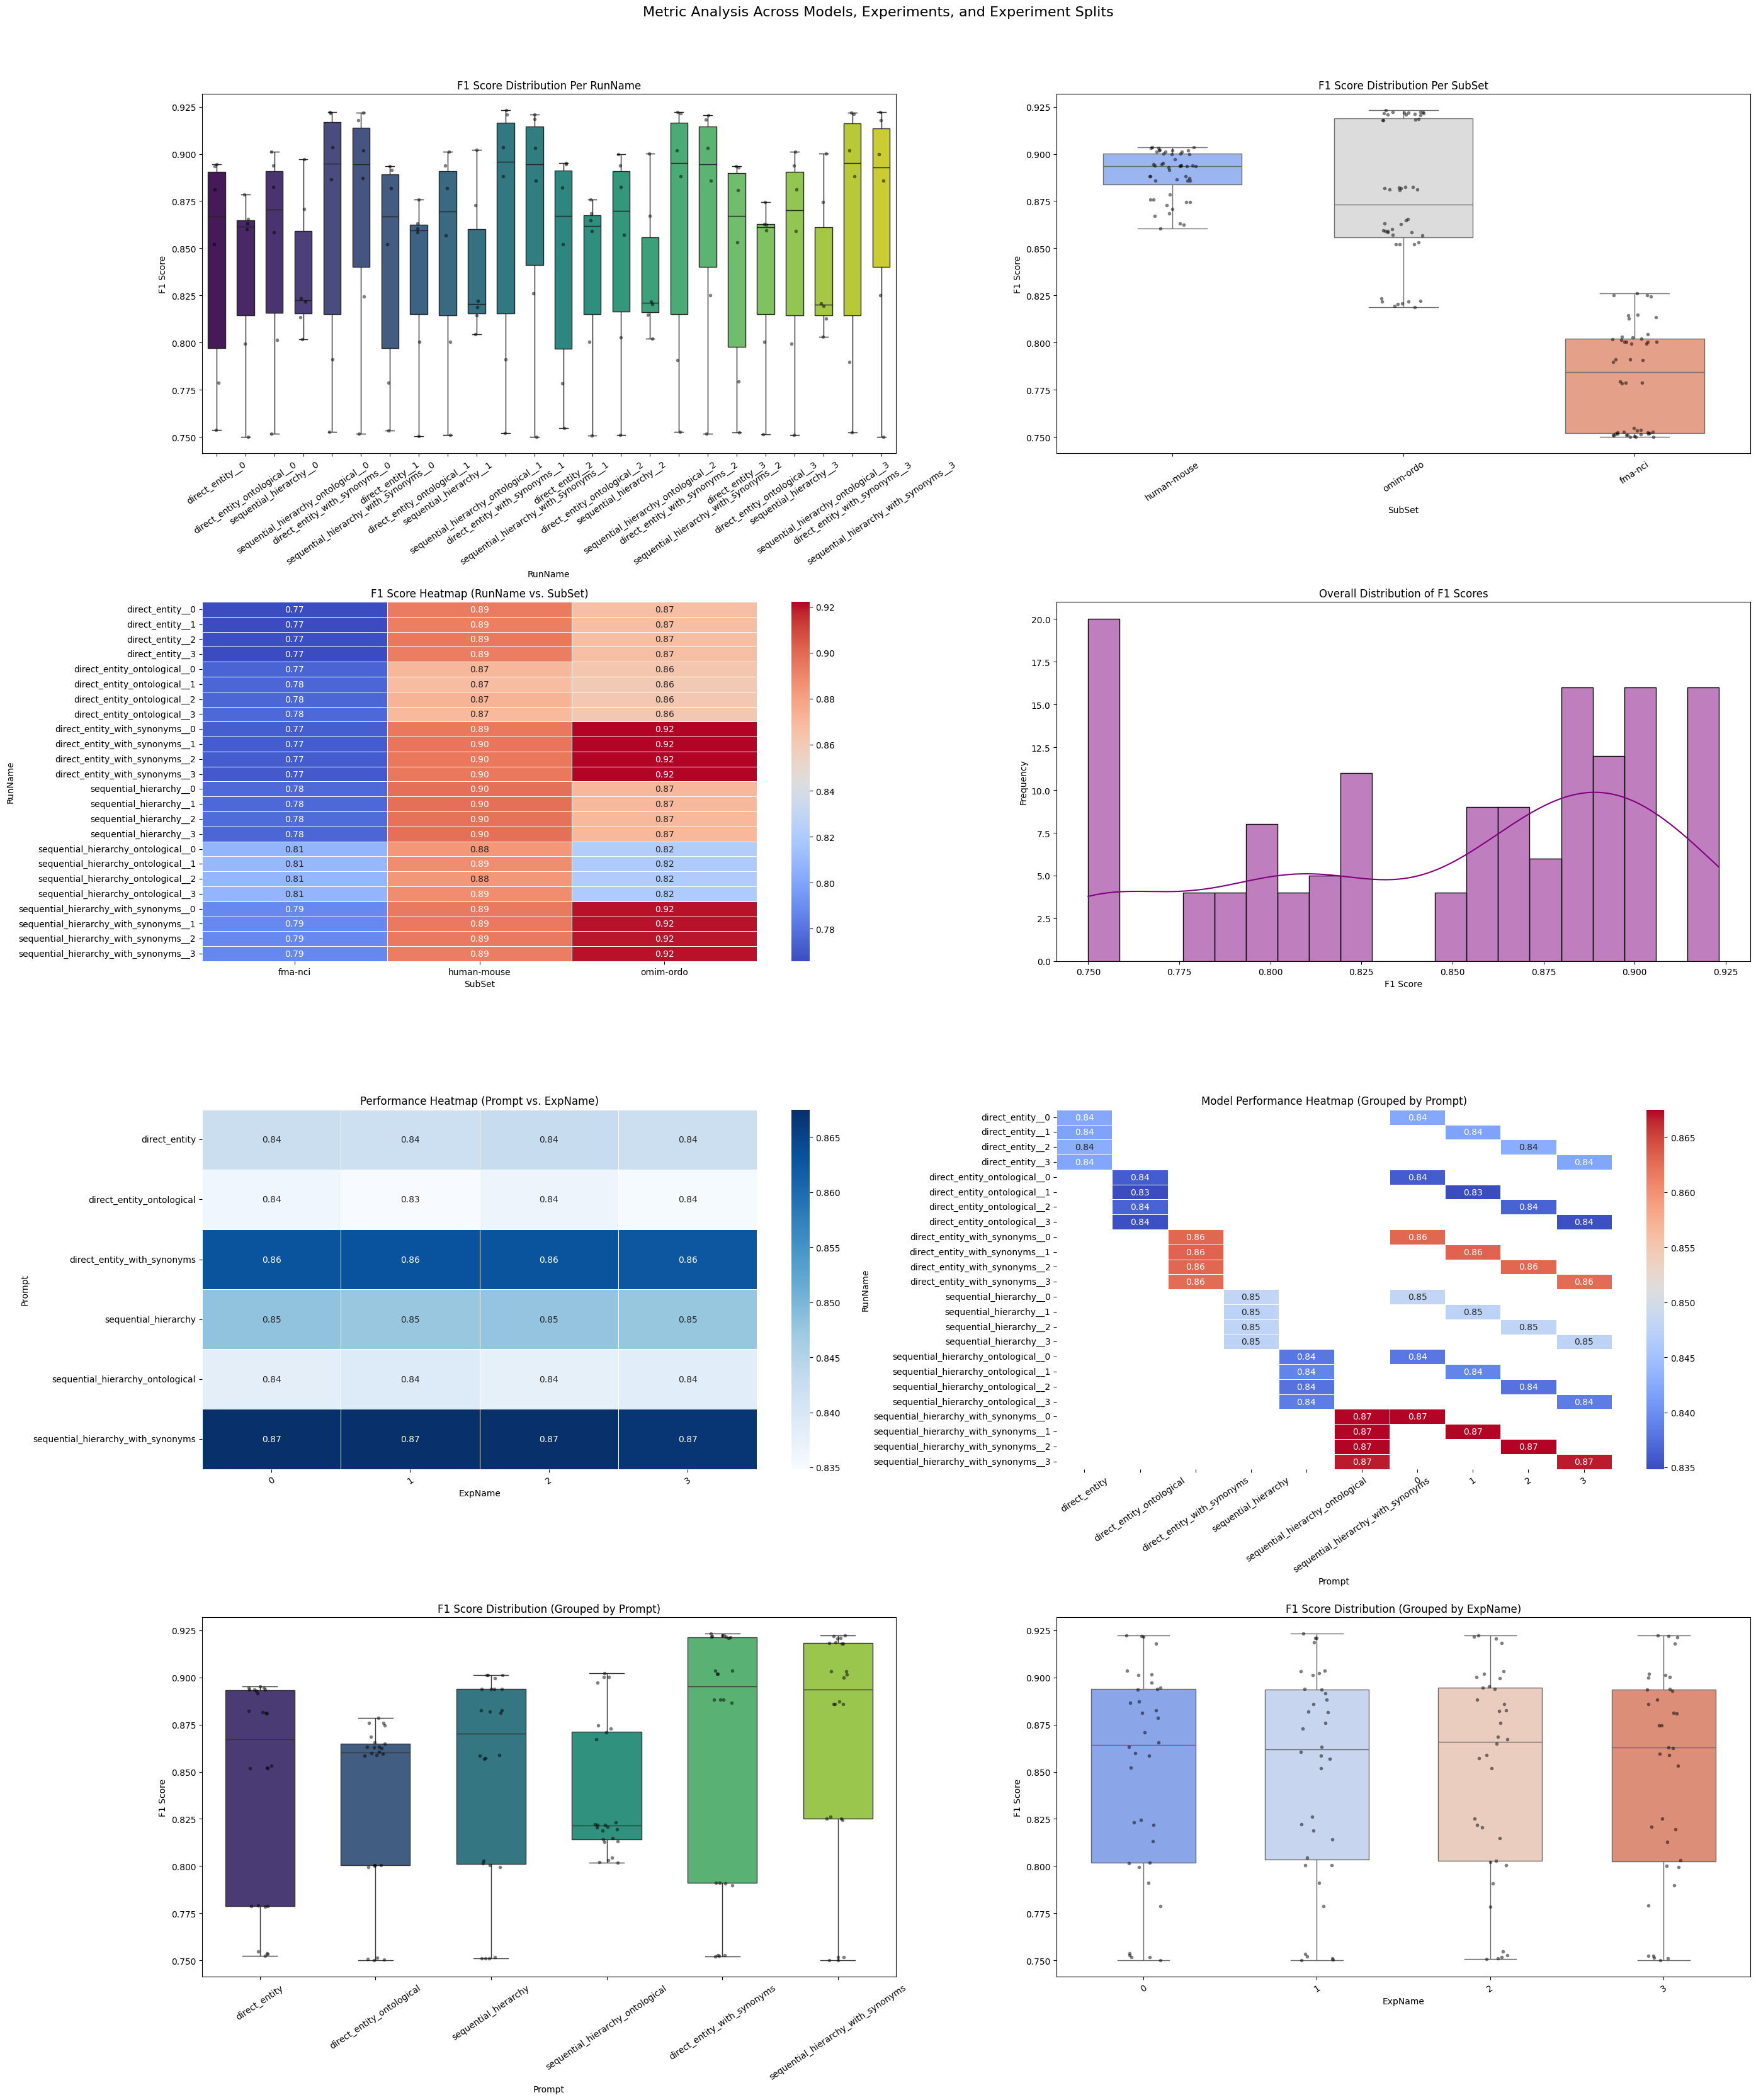

In [28]:
metrics_df = results_df.copy()
metric = "F1 Score"

experiment_col, left_col, right_col = "SubSet", "Prompt", "ExpName"

plot_detaild_analysis(
    metrics_df=metrics_df,
    metric=metric,
    run_col_name="RunName",
    experiment_col=experiment_col,
    left_col=left_col,
    right_col=right_col,
    left_col_name="leftPart",
    right_col_name="rightPart",
    run_separator="__",
)